# Treinamento e Análise de Performance — Farol.Edu (Top 15 Consolidado)

Este notebook realiza o treinamento supervisionado, a avaliação de métricas (RNF03) e a calibração de limiares sobre a base final pré-processada (`ENEM_2023_3ANO_TOP15.parquet`), composta pelos 15 atributos sociológicos de maior relevância e pelos indicadores consolidados de produto (`VEICULO_PROPRIO`, `REFRIGERACAO` e `CONECTIVIDADE`).

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    f1_score,
    recall_score,
    precision_score,
    accuracy_score
)

# Carregar a base final enxuta (15 features + 1 target)
caminho_arquivo = 'ENEM_2023_3ANO_TOP15.parquet'
df = pd.read_parquet(caminho_arquivo)

print(f"Dimensões do Dataset: {df.shape[0]:,} alunos e {df.shape[1]} colunas.")
print("\nProporção das Classes (RISCO_DEFASAGEM):")
print(df['RISCO_DEFASAGEM'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

# Separar Features (X) e Variável-Alvo (y)
X = df.drop(columns=['RISCO_DEFASAGEM'])
y = df['RISCO_DEFASAGEM']

# Divisão Estratificada: 80% Treino e 20% Teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"\nRegistros de Treino (80%): {X_train.shape[0]:,}")
print(f"Registros de Teste  (20%): {X_test.shape[0]:,}")

Dimensões do Dataset: 681,357 alunos e 16 colunas.

Proporção das Classes (RISCO_DEFASAGEM):
RISCO_DEFASAGEM
0    75.0%
1    25.0%
Name: proportion, dtype: object

Registros de Treino (80%): 545,085
Registros de Teste  (20%): 136,272


## 1. Treinamento dos Modelos de Classificação

Treinamos e comparamos dois algoritmos baseados em árvores de decisão utilizando ponderação de classes (`class_weight='balanced'`) para compensar a proporção natural de 25% de alunos no 1º quartil e maximizar o **Recall** (detecção de estudantes vulneráveis):
1. **LightGBM Classifier (`LGBMClassifier`):** Modelo principal (*Gradient Boosting*).
2. **Random Forest Classifier (`RandomForestClassifier`):** Modelo comparativo (*Bagging*).

In [8]:
# 1. Treinar o LightGBM (Modelo Principal)
print("Treinando LightGBM Classifier...")
modelo_lgbm = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=8,
    num_leaves=63,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
modelo_lgbm.fit(X_train, y_train)

# 2. Treinar o Random Forest (Modelo Comparativo)
print("Treinando Random Forest Classifier...")
modelo_rf = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    min_samples_leaf=20,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
modelo_rf.fit(X_train, y_train)

print("✅ Treinamento finalizado com sucesso!")

Treinando LightGBM Classifier...
Treinando Random Forest Classifier...
✅ Treinamento finalizado com sucesso!


## 2. Análise de Performance e Validação (RNF03)

Avaliamos a capacidade preditiva dos modelos sobre os 20% de dados de teste utilizando **Precision**, **Recall**, **F1-Score**, **Acurácia**, **Matriz de Confusão** e a **Curva ROC (AUC)**.

==================== LightGBM Classifier (Top 15) ====================
                     precision    recall  f1-score   support

        0 - Regular       0.88      0.66      0.75    102205
1 - Risco Defasagem       0.41      0.72      0.52     34067

           accuracy                           0.67    136272
          macro avg       0.64      0.69      0.64    136272
       weighted avg       0.76      0.67      0.70    136272

ROC-AUC Score: 0.7578

==================== Random Forest Classifier (Top 15) ====================
                     precision    recall  f1-score   support

        0 - Regular       0.87      0.65      0.75    102205
1 - Risco Defasagem       0.41      0.72      0.52     34067

           accuracy                           0.67    136272
          macro avg       0.64      0.69      0.63    136272
       weighted avg       0.76      0.67      0.69    136272

ROC-AUC Score: 0.7541



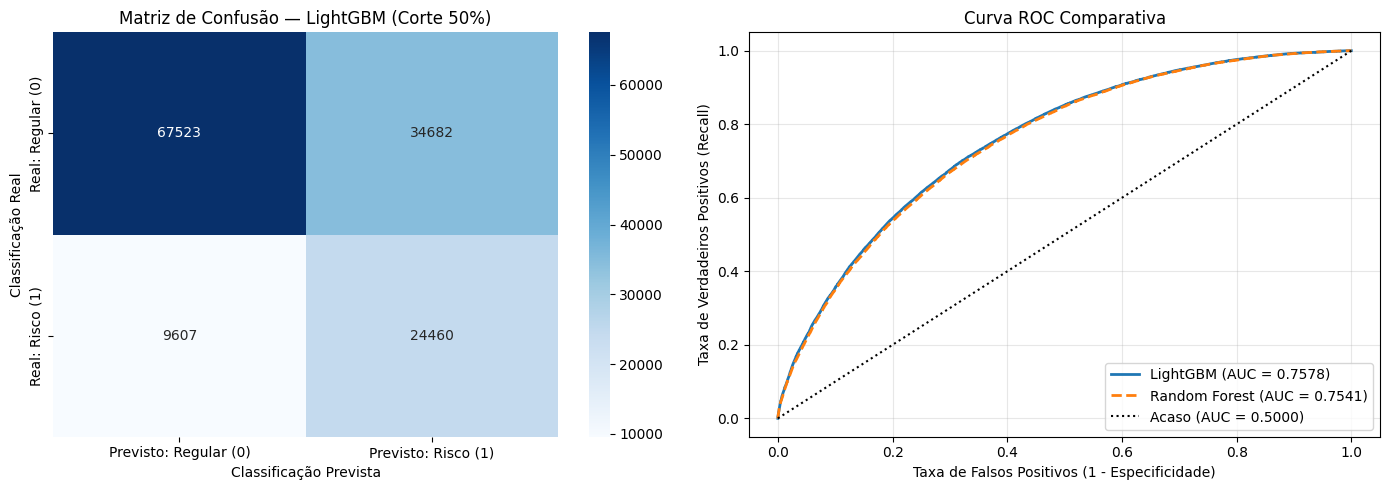

In [9]:
def avaliar_modelo(nome, modelo, X_teste, y_teste):
    y_pred = modelo.predict(X_teste)
    y_proba = modelo.predict_proba(X_teste)[:, 1]

    print(f"==================== {nome} ====================")
    print(classification_report(y_teste, y_pred, target_names=['0 - Regular', '1 - Risco Defasagem']))

    auc = roc_auc_score(y_teste, y_proba)
    print(f"ROC-AUC Score: {auc:.4f}\n")
    return y_pred, y_proba, auc

y_pred_lgbm, y_proba_lgbm, auc_lgbm = avaliar_modelo("LightGBM Classifier (Top 15)", modelo_lgbm, X_test, y_test)
y_pred_rf, y_proba_rf, auc_rf = avaliar_modelo("Random Forest Classifier (Top 15)", modelo_rf, X_test, y_test)

# Plotar Matriz de Confusão (LightGBM) e Curva ROC Comparativa
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Matriz de Confusão
cm = confusion_matrix(y_test, y_pred_lgbm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Previsto: Regular (0)', 'Previsto: Risco (1)'],
            yticklabels=['Real: Regular (0)', 'Real: Risco (1)'])
axes[0].set_title('Matriz de Confusão — LightGBM (Corte 50%)')
axes[0].set_ylabel('Classificação Real')
axes[0].set_xlabel('Classificação Prevista')

# Gráfico 2: Curva ROC
fpr_lgbm, tpr_lgbm, _ = roc_curve(y_test, y_proba_lgbm)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)

axes[1].plot(fpr_lgbm, tpr_lgbm, label=f'LightGBM (AUC = {auc_lgbm:.4f})', linewidth=2)
axes[1].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.4f})', linewidth=2, linestyle='--')
axes[1].plot([0, 1], [0, 1], 'k:', label='Acaso (AUC = 0.5000)')
axes[1].set_title('Curva ROC Comparativa')
axes[1].set_xlabel('Taxa de Falsos Positivos (1 - Especificidade)')
axes[1].set_ylabel('Taxa de Verdadeiros Positivos (Recall)')
axes[1].legend(loc='lower right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Importância das Variáveis (Feature Importance)

Inspecionamos o peso de cada um dos 15 atributos (incluindo as novas variáveis agregadas `VEICULO_PROPRIO`, `REFRIGERACAO` e `CONECTIVIDADE`) na tomada de decisão do modelo LightGBM.

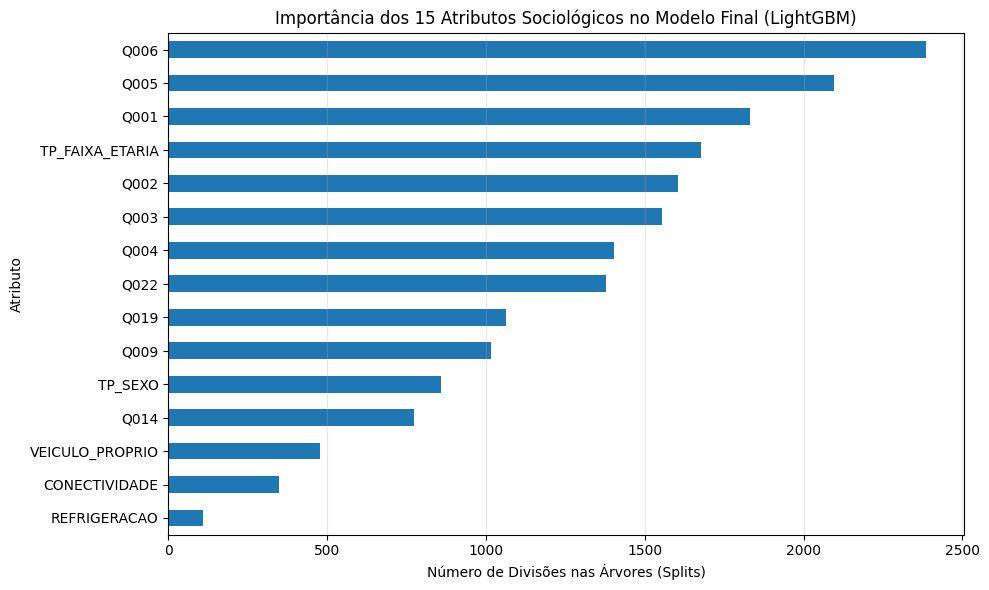

Ranking numérico de relevância:
   1. Q006               -> Score: 2385
   2. Q005               -> Score: 2096
   3. Q001               -> Score: 1831
   4. TP_FAIXA_ETARIA    -> Score: 1678
   5. Q002               -> Score: 1606
   6. Q003               -> Score: 1555
   7. Q004               -> Score: 1403
   8. Q022               -> Score: 1377
   9. Q019               -> Score: 1062
  10. Q009               -> Score: 1016
  11. TP_SEXO            -> Score: 859
  12. Q014               -> Score: 775
  13. VEICULO_PROPRIO    -> Score: 478
  14. CONECTIVIDADE      -> Score: 348
  15. REFRIGERACAO       -> Score: 109


In [10]:
importancias = pd.Series(modelo_lgbm.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
importancias.plot(kind='barh', color='#1f77b4')
plt.title('Importância dos 15 Atributos Sociológicos no Modelo Final (LightGBM)')
plt.xlabel('Número de Divisões nas Árvores (Splits)')
plt.ylabel('Atributo')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print("Ranking numérico de relevância:")
for i, (col, score) in enumerate(importancias.sort_values(ascending=False).items(), 1):
    print(f"  {i:2d}. {col:<18} -> Score: {score}")

## 4. Calibração de Limiares (Semáforo Pedagógico — RF03)

Testamos diferentes pontos de corte de probabilidade (`45%` a `70%`) para calibrar as três faixas de alerta do painel do gestor educacional:
* 🔴 **Crítico (`>= 65%`):** Foco em alta precisão para intervenção pedagógica imediata.
* 🟡 **Atenção (`50% a 64,9%`):** Maximiza o *F1-Score* e eleva o *Recall* para monitoramento preventivo.
* 🟢 **Regular (`< 50%`):** Desempenho regular esperado.

In [11]:
limiares = [0.45, 0.50, 0.55, 0.60, 0.65, 0.70]
resultados_limiar = []

for t in limiares:
    pred_custom = (y_proba_lgbm >= t).astype(int)
    resultados_limiar.append({
        'Limiar (Corte %)': f"{int(t*100)}%",
        'Acurácia Geral': round(accuracy_score(y_test, pred_custom), 3),
        'Precision (Risco)': round(precision_score(y_test, pred_custom), 3),
        'Recall (Risco Capturado)': round(recall_score(y_test, pred_custom), 3),
        'F1-Score (Risco)': round(f1_score(y_test, pred_custom), 3),
        'Total Alunos em Alerta': int(pred_custom.sum()),
        '% da Turma em Alerta': f"{round((pred_custom.sum() / len(y_test)) * 100, 1)}%"
    })

df_limiares = pd.DataFrame(resultados_limiar)
print("=== Comportamento do Modelo por Faixa de Alerta no Dashboard ===")
display(df_limiares)

=== Comportamento do Modelo por Faixa de Alerta no Dashboard ===


,Limiar (Corte %),Acurácia Geral,Precision (Risco),Recall (Risco Capturado),F1-Score (Risco),Total Alunos em Alerta,% da Turma em Alerta
0,45%,0.637,0.388,0.784,0.519,68764,50.5%
1,50%,0.675,0.414,0.718,0.525,59142,43.4%
2,55%,0.708,0.442,0.636,0.522,49075,36.0%
3,60%,0.735,0.474,0.551,0.509,39609,29.1%
4,65%,0.754,0.509,0.450,0.477,30107,22.1%
5,70%,0.764,0.546,0.342,0.420,21314,15.6%


## 5. Exportação do Modelo Final para Produção (Backend FastAPI)

Exportamos o pacote `modelo_risco_defasagem_top15.joblib` contendo o modelo treinado, a lista ordenada das 15 colunas e os limiares do semáforo pedagógico.

In [12]:
artefato_deploy = {
    'modelo': modelo_lgbm,
    'colunas_features': list(X.columns),
    'metrica_auc_teste': round(auc_lgbm, 4),
    'limiares_semaforo': {
        'atencao': 0.50,
        'critico': 0.65
    }
}

nome_joblib = 'modelo_risco_defasagem_top15.joblib'
joblib.dump(artefato_deploy, nome_joblib, compress=3)
print(f"🚀 Artefato '{nome_joblib}' exportado com sucesso!")

# Simulação rápida de predição de um aluno para o Dashboard
pacote = joblib.load(nome_joblib)
modelo_api = pacote['modelo']
colunas_api = pacote['colunas_features']

exemplo_aluno = X_test.iloc[[0]][colunas_api]
prob_risco = float(modelo_api.predict_proba(exemplo_aluno)[0, 1])

if prob_risco >= pacote['limiares_semaforo']['critico']:
    status = "🔴 CRITICO (Intervenção Imediata)"
elif prob_risco >= pacote['limiares_semaforo']['atencao']:
    status = "🟡 ATENCAO (Monitoramento Preventivo)"
else:
    status = "🟢 REGULAR (Acompanhamento Padrão)"

print("\n--- Teste de Predição para a API ---")
print(f"Colunas de entrada ({len(colunas_api)}): {colunas_api}")
print(f"Probabilidade de Defasagem: {prob_risco*100:.1f}%")
print(f"Classificação no Dashboard: {status}")

🚀 Artefato 'modelo_risco_defasagem_top15.joblib' exportado com sucesso!

--- Teste de Predição para a API ---
Colunas de entrada (15): ['TP_FAIXA_ETARIA', 'TP_SEXO', 'Q001', 'Q002', 'Q003', 'Q004', 'Q005', 'Q006', 'Q009', 'Q014', 'Q019', 'Q022', 'VEICULO_PROPRIO', 'REFRIGERACAO', 'CONECTIVIDADE']
Probabilidade de Defasagem: 26.0%
Classificação no Dashboard: 🟢 REGULAR (Acompanhamento Padrão)


## 6. Converter a Árvore em Código TypeScript/JS Puro (m2cgen) — Mais Simples e Sem Dependências

Para rodar o modelo LightGBM diretamente em um backend TypeScript (Express, Fastify ou NestJS), basta rodar uma célula rápida no seu Colab para exportar o modelo em um formato nativo para o TypeScript.

Como um modelo LightGBM já treinado nada mais é do que uma sequência de desvios condicionais (if / else) das 300 árvores somada a uma função logística, a biblioteca m2cgen (Model 2 Code Generator) transpila o seu modelo diretamente para uma função JavaScript/TypeScript nativa.
* **Vantagem para o projeto acadêmico**: Zero bibliotecas pesadas em C++ no *npm
install*, roda em qualquer hospedagem gratuita (Vercel, Render, Railway) e executa a predição em menos de 1 milissegundo.

In [15]:
!pip install -q m2cgen
import m2cgen as m2c

# Converte o modelo_lgbm já treinado em uma função JavaScript pura (score)
codigo_ts = m2c.export_to_javascript(modelo_lgbm, function_name="calcularScoreModelo")

with open("modeloLightGBM.ts", "w") as f:
    f.write("export " + codigo_ts)

print("✅ Arquivo 'modeloLightGBM.ts' gerado! Basta baixá-lo e colocar na pasta src/ do seu Backend.")

✅ Arquivo 'modeloLightGBM.ts' gerado! Basta baixá-lo e colocar na pasta src/ do seu Backend.
